# Hotel Demand Dataset: Exploratory Data Analysis and Preprocessing

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [6]:
raw_data= pd.read_csv("../data/raw/H2.csv", skipinitialspace=True)
raw_data.head(800)

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6.0,NaN,0,Transient,0.0,0,0,Check-Out,7/3/2015
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,1,Canceled,7/1/2015
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9.0,NaN,0,Transient,68.0,0,1,Canceled,4/30/2015
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,2,Canceled,6/23/2015
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9.0,NaN,0,Transient,76.5,0,1,Canceled,4/2/2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,1,30,2015,August,32,8,2,1,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Canceled,8/1/2015
796,0,124,2015,August,32,8,2,1,2,0.0,...,No Deposit,17.0,NaN,0,Transient-Party,94.5,0,0,Check-Out,8/11/2015
797,1,124,2015,August,32,8,2,1,2,0.0,...,No Deposit,17.0,NaN,0,Transient-Party,94.5,0,0,Canceled,8/1/2015
798,1,30,2015,August,32,8,2,1,2,0.0,...,No Deposit,1.0,NaN,0,Transient-Party,86.0,0,0,Canceled,8/1/2015


# handle missing values

In [7]:
len(raw_data.index)

79330

In [8]:
for i in raw_data.columns:
    if raw_data[i].isna().sum() !=0:
        print('Null values in', i, 'column:', raw_data[i].isna().sum())       

Null values in Children column: 4
Null values in Country column: 24
Null values in Agent column: 8131
Null values in Company column: 75641


In [9]:
#most of company names are missing, so we will drop this column
raw_data = raw_data.drop(columns=['Company'])
#null values of children and country are insignificant, so we will drop these rows
raw_data = raw_data.dropna(subset=['Children', 'Country'])
#agent nan values will be replaced with , as no agent was used for these bookings
raw_data['Agent'] = raw_data['Agent'].fillna(0)

In [10]:
raw_data.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,0,No Deposit,6.0,0,Transient,0.0,0,0,Check-Out,7/3/2015
1,1,88,2015,July,27,1,0,4,2,0.0,...,0,No Deposit,9.0,0,Transient,76.5,0,1,Canceled,7/1/2015
2,1,65,2015,July,27,1,0,4,1,0.0,...,0,No Deposit,9.0,0,Transient,68.0,0,1,Canceled,4/30/2015
3,1,92,2015,July,27,1,2,4,2,0.0,...,0,No Deposit,9.0,0,Transient,76.5,0,2,Canceled,6/23/2015
4,1,100,2015,July,27,2,0,2,2,0.0,...,0,No Deposit,9.0,0,Transient,76.5,0,1,Canceled,4/2/2015


# removing whitespaces from strings 

In [11]:
#removal of leading and trailing spaces in text columns
text_cols = raw_data.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    raw_data[col] = raw_data[col].str.strip()

#checking the removal of leading and trailing spaces
for col in text_cols:
    if raw_data[col].str.startswith(" ").any() or raw_data[col].str.endswith(" ").any():
        print(f"Leading or trailing spaces found in column: {col}")
    else:
        print(f"No leading or trailing spaces in column: {col}")

No leading or trailing spaces in column: ArrivalDateMonth
No leading or trailing spaces in column: Meal
No leading or trailing spaces in column: Country
No leading or trailing spaces in column: MarketSegment
No leading or trailing spaces in column: DistributionChannel
No leading or trailing spaces in column: ReservedRoomType
No leading or trailing spaces in column: AssignedRoomType
No leading or trailing spaces in column: DepositType
No leading or trailing spaces in column: CustomerType
No leading or trailing spaces in column: ReservationStatus
No leading or trailing spaces in column: ReservationStatusDate


# converting meal colomns to be more understandable

In [12]:
#replace Undefined,BB,FB,HB,SC to its meaning 
raw_data["Meal"] = raw_data["Meal"].replace({
    "Undefined": "undefined",
    "BB": "Breakfast",
    "FB": "Full Board",
    "HB": "Half Board",
    "SC": "self Catering"
})
display(raw_data["Meal"])

0        Half Board
1         Breakfast
2         Breakfast
3         Breakfast
4         Breakfast
            ...    
79325     Breakfast
79326     Breakfast
79327     Breakfast
79328     Breakfast
79329    Half Board
Name: Meal, Length: 79302, dtype: str

# changing datatypes

In [13]:
# Convert numerical columns to integers
raw_data["Children"] = raw_data["Children"].astype(int)
raw_data["Agent"] = raw_data["Agent"].astype(int)

# Convert date column
raw_data["ReservationStatusDate"] = pd.to_datetime(
    raw_data["ReservationStatusDate"]
)

# Verify data types
raw_data.dtypes

IsCanceled                              int64
LeadTime                                int64
ArrivalDateYear                         int64
ArrivalDateMonth                          str
ArrivalDateWeekNumber                   int64
ArrivalDateDayOfMonth                   int64
StaysInWeekendNights                    int64
StaysInWeekNights                       int64
Adults                                  int64
Children                                int64
Babies                                  int64
Meal                                      str
Country                                   str
MarketSegment                             str
DistributionChannel                       str
IsRepeatedGuest                         int64
PreviousCancellations                   int64
PreviousBookingsNotCanceled             int64
ReservedRoomType                          str
AssignedRoomType                          str
BookingChanges                          int64
DepositType                       

# handling duplicate values

In [14]:
#to know number of duplicates
print('Duplicate values are:', raw_data.duplicated().sum())

Duplicate values are: 25886


In [15]:
duplicates = raw_data[raw_data.duplicated(keep=False)]

duplicates.sort_values(
    by=list(raw_data.columns)
).head(20)

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
712,0,0,2015,August,32,7,0,2,2,0,...,0,No Deposit,14,0,Transient,75.0,0,1,Check-Out,2015-08-09
742,0,0,2015,August,32,7,0,2,2,0,...,0,No Deposit,14,0,Transient,75.0,0,1,Check-Out,2015-08-09
761,0,0,2015,August,32,8,0,1,2,0,...,0,No Deposit,9,0,Transient,89.0,0,1,Check-Out,2015-08-09
778,0,0,2015,August,32,8,0,1,2,0,...,0,No Deposit,9,0,Transient,89.0,0,1,Check-Out,2015-08-09
36732,0,0,2015,August,33,10,1,0,2,0,...,0,No Deposit,0,0,Transient,75.0,0,0,Check-Out,2015-08-11
36733,0,0,2015,August,33,10,1,0,2,0,...,0,No Deposit,0,0,Transient,75.0,0,0,Check-Out,2015-08-11
36734,0,0,2015,August,33,10,1,0,2,0,...,0,No Deposit,0,0,Transient,75.0,0,0,Check-Out,2015-08-11
1007,0,0,2015,August,33,11,0,1,1,0,...,0,No Deposit,0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
1013,0,0,2015,August,33,11,0,1,1,0,...,0,No Deposit,0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
1011,0,0,2015,August,33,11,0,1,2,0,...,0,No Deposit,0,0,Transient,80.0,0,0,Check-Out,2015-08-12


In [16]:
#dropping all duplicates except the first occurrence
raw_data = raw_data.drop_duplicates(keep='first')
len(raw_data.index)

53416


# handling outliers and invalid values

In [17]:
raw_data.describe().T


,count,mean,min,25%,50%,75%,max,std
IsCanceled,53416.0,0.300303,0.0,0.0,0.0,1.0,1.0,0.458394
LeadTime,53416.0,77.691328,0.0,14.0,50.0,118.0,629.0,82.114395
ArrivalDateYear,53416.0,2016.2541,2015.0,2016.0,2016.0,2017.0,2017.0,0.659213
ArrivalDateWeekNumber,53416.0,26.635409,1.0,16.0,27.0,37.0,53.0,13.58609
ArrivalDateDayOfMonth,53416.0,15.755972,1.0,8.0,16.0,23.0,31.0,8.801847
StaysInWeekendNights,53416.0,0.872154,0.0,0.0,1.0,2.0,16.0,0.913685
StaysInWeekNights,53416.0,2.274431,0.0,1.0,2.0,3.0,41.0,1.618195
Adults,53416.0,1.876442,0.0,2.0,2.0,2.0,4.0,0.544122
Children,53416.0,0.131871,0.0,0.0,0.0,0.0,3.0,0.442206
Babies,53416.0,0.007339,0.0,0.0,0.0,0.0,10.0,0.102676


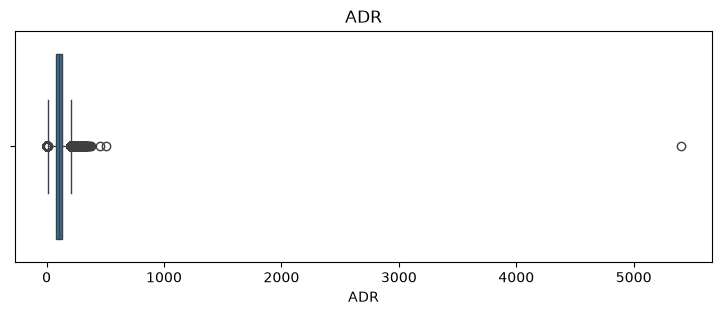

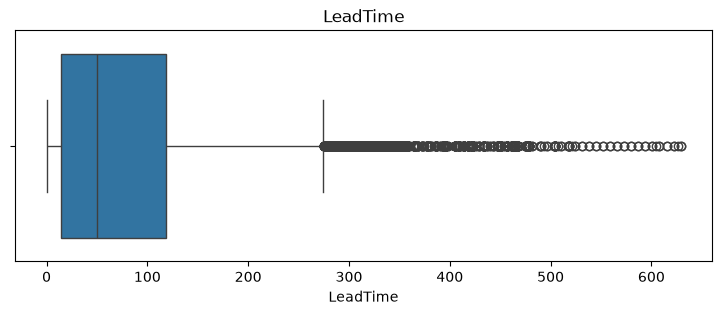

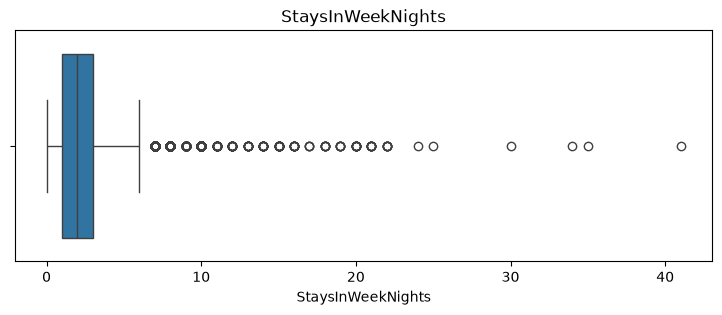

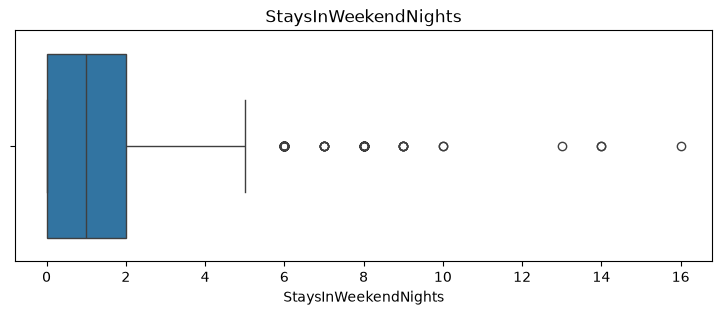

In [18]:
#when inspecting the quartiles , we can say that some data has unusual values 
#inspecting the boxplots of the numerical columns will help us to identify the outliers
columns = [
    "ADR",
    "LeadTime",
    "StaysInWeekNights",
    "StaysInWeekendNights"
]

for col in columns:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=raw_data[col])
    plt.title(col)
    plt.show()


In [19]:

#also inspecting the IQR values will help us to identify the outliers
columns = [
    "ADR",
    "LeadTime",
    "StaysInWeekNights",
    "StaysInWeekendNights"
]

for col in columns:
    Q1 = raw_data[col].quantile(0.25)
    Q3 = raw_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = raw_data[
        (raw_data[col] < lower) |
        (raw_data[col] > upper)
    ]

    print(col, len(outliers))

ADR 2487
LeadTime 1697
StaysInWeekNights 686
StaysInWeekendNights 80


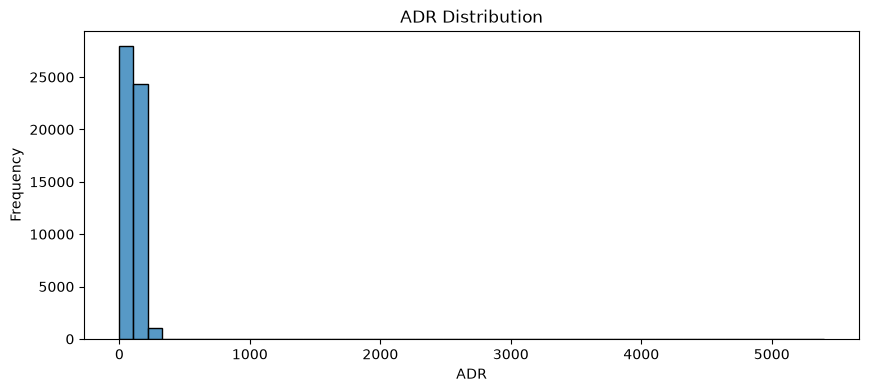

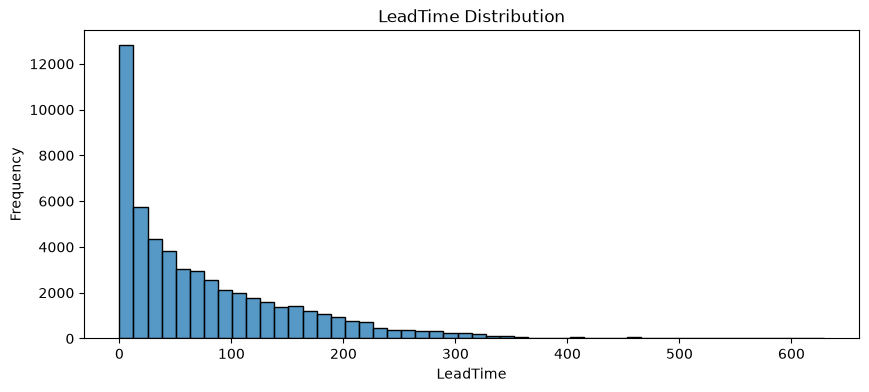

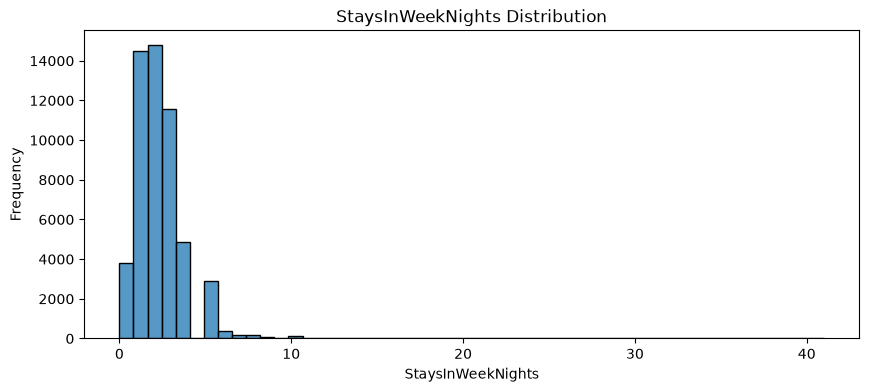

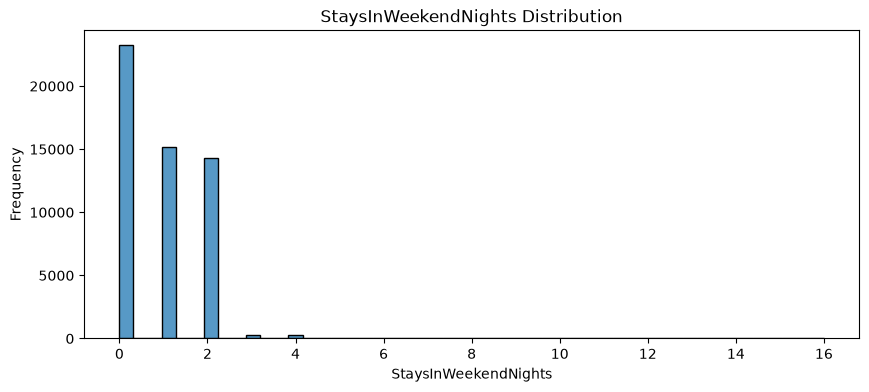

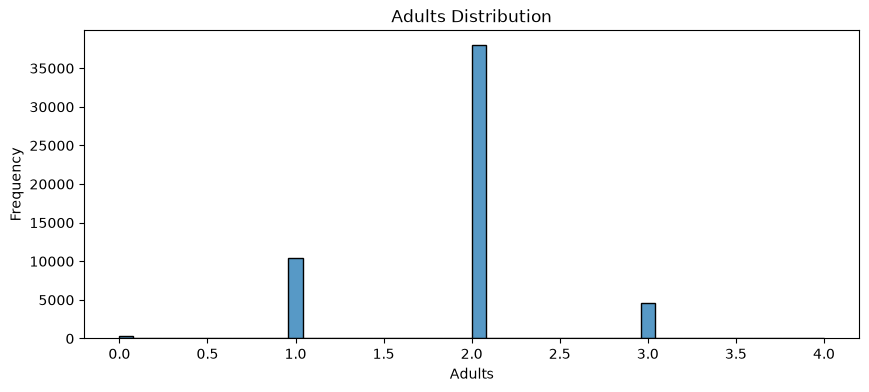

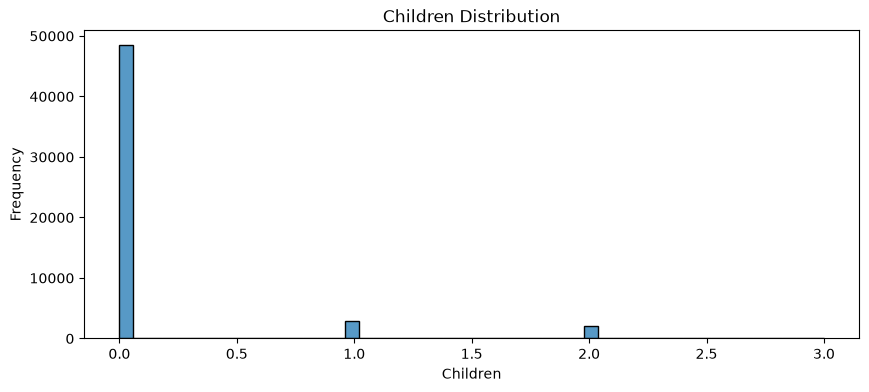

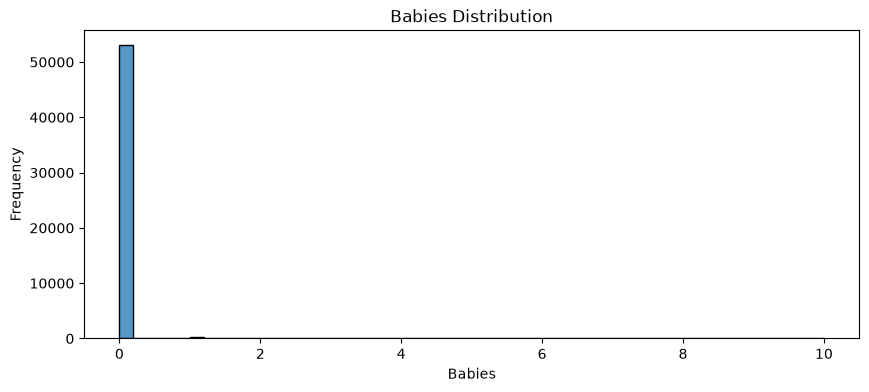

In [20]:
#inspecting histograms of the numerical columns will help us to identify the outliers
columns = [
    "ADR",
    "LeadTime",
    "StaysInWeekNights",
    "StaysInWeekendNights",
    "Adults",
    "Children",
    "Babies"
]

for col in columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(data=raw_data, x=col, bins=50)
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [21]:
check = raw_data[raw_data["ADR"] >= 500].copy()
display(check)

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
8455,1,35,2016,March,13,25,0,1,2,0,...,1,Non Refund,12,0,Transient,5400.0,0,0,Canceled,2016-02-19
71343,0,0,2017,May,19,9,0,1,1,0,...,0,No Deposit,159,0,Transient,510.0,0,0,Check-Out,2017-05-10


# checking invalid values

In [22]:
columns = [
    "LeadTime",
    "Adults",
    "Children",
    "Babies",
    "StaysInWeekNights",
    "StaysInWeekendNights",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "BookingChanges",
    "DaysInWaitingList",
    "RequiredCarParkingSpaces",
    "TotalOfSpecialRequests"
]

for col in columns:
    print(col, (raw_data[col] < 0).sum())

LeadTime 0
Adults 0
Children 0
Babies 0
StaysInWeekNights 0
StaysInWeekendNights 0
PreviousCancellations 0
PreviousBookingsNotCanceled 0
BookingChanges 0
DaysInWaitingList 0
RequiredCarParkingSpaces 0
TotalOfSpecialRequests 0


# checking logically inconsistent data

In [23]:
# Bookings with no guests
no_guests = (raw_data["Adults"] + raw_data["Children"] + raw_data["Babies"]) == 0

not_cancelled = raw_data["IsCanceled"] == 0

result = raw_data[no_guests & not_cancelled]

display(result)
print("Total records:", len(result))

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
332,0,132,2015,July,30,23,2,5,0,0,...,4,No Deposit,1,0,Transient-Party,0.00,0,0,Check-Out,2015-07-30
862,0,0,2015,August,33,9,2,0,0,0,...,0,No Deposit,9,0,Contract,0.00,0,0,Check-Out,2015-08-11
960,0,0,2015,August,33,10,9,20,0,0,...,20,No Deposit,0,0,Transient,0.00,0,0,Check-Out,2015-09-08
996,0,0,2015,August,33,11,0,4,0,0,...,4,No Deposit,0,0,Transient-Party,0.00,0,1,Check-Out,2015-08-15
2531,0,0,2015,September,37,7,1,4,0,0,...,2,No Deposit,11,0,Transient,0.00,0,1,Check-Out,2015-09-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74969,0,107,2017,June,26,27,0,3,0,0,...,1,No Deposit,7,0,Transient,100.80,0,0,Check-Out,2017-06-30
75031,0,1,2017,June,26,30,0,1,0,0,...,0,No Deposit,0,0,Transient,0.00,1,1,Check-Out,2017-07-01
76191,0,44,2017,July,28,15,1,1,0,0,...,2,No Deposit,425,0,Transient,73.80,0,0,Check-Out,2017-07-17
76474,0,2,2017,July,28,15,2,5,0,0,...,1,No Deposit,9,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22


Total records: 140


In [24]:
#removing bookings with no guests and not cancelled
raw_data = raw_data[~(no_guests & not_cancelled)]
#removing very unusual datapoint of adr 
raw_data = raw_data[raw_data["ADR"] != 5400].copy()
len(raw_data.index)

53275

# exporting cleaned data 

In [26]:
raw_data.to_csv("../data/processed_EDA/H2_cleaned.csv", index=False)